# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Дисциплина:** «Анализ больших данных и программные средства сбора данных»  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. По желанию — выгрузить витрину в BigQuery и повторить расчёт там (пошаговая инструкция ниже).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

> 🧑‍🏫 **Версия для преподавателя.** Содержит полное решение варианта 30, ключи проверки, чеклист приёмки и разбор типичных ошибок.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 1                 #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return found[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 1 — Авиаперевозки
Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»

CSV  : Авиакомпании        (справочник субъектов)
XLSX : Рейсы          (события, объём в единицах: пассажиров)
JSON : Билеты          (цены, разрез: класс билета)

Объём генерации: субъектов 9, событий 3 500, уровень дефектов ★★
Аналитическая задача: Сезонность перевозок: в каком месяце выручка максимальна и какие компании её
формируют


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        "route": [f"{a} — {b}" for a, b in zip(rng.choice(regions, m), rng.choice(regions, m))],
        "volume_units": volume,
        "asset_type": rng.choice(["Тип A", "Тип B", "Тип C", "Тип D"], m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = [f"{cfg['cls']} 1", f"{cfg['cls']} 2", f"{cfg['cls']} 3"]
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       10   размер:      0.7 КБ
events.xlsx     строк:    3 500   размер:    130.1 КБ
prices.json     строк:    6 966   размер:    888.1 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества { display-mode: "form" }
# ---------------------------------------------------------------- загрузка «как есть»
# dtype=str — чтобы pandas не «помог» с типами и не скрыл проблему.
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Профиль источника: тип, заполненность, уникальность, примеры."""
    rows = []
    for col in df.columns:
        s = df[col]
        non_null = s.notna() & (s.astype(str).str.strip() != "")
        sample = s[non_null].astype(str).head(2).tolist()
        rows.append({
            "источник": name, "колонка": col, "тип": str(s.dtype),
            "заполнено, %": round(float(non_null.mean()) * 100, 1),
            "уникальных": int(s.nunique(dropna=True)),
            "пример": " | ".join(sample)[:42],
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
print("ПРОФИЛЬ ИСТОЧНИКОВ")
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
# Приводим «почти числа» к числу — чтобы ловить отрицательные цены и выбросы.
def numeric_like(series):
    cleaned = (series.astype(str)
               .str.replace("\u00a0", " ", regex=False)
               .str.replace(r"[^\d,.\-]", "", regex=True)
               .str.replace(" ", "", regex=False))
    # запятая как десятичный разделитель, если нет точки; иначе — разделитель разрядов
    cleaned = np.where(cleaned.str.contains(",") & cleaned.str.contains(r"\."),
                       cleaned.str.replace(",", "", regex=False),
                       cleaned.str.replace(",", ".", regex=False))
    return pd.to_numeric(pd.Series(cleaned, index=series.index), errors="coerce")

issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

# --- Полнота
for name, df in SOURCES.items():
    for col in df.columns:
        miss = int(df[col].isna().sum() + (df[col].astype(str).str.strip() == "").sum())
        if miss:
            add_issue("Полнота", name, f"пропуски в «{col}»", miss,
                      "оставить NaN, исключить из расчёта, но сохранить строку")

# --- Уникальность
dup_entities = int(raw_entities.duplicated().sum())
if dup_entities:
    add_issue("Уникальность", "CSV", "полные дубликаты строк справочника", dup_entities,
              "удалить дубликаты (по ключу entity_id)")

dup_key_events = int(raw_events["event_id"].duplicated().sum())
if dup_key_events:
    add_issue("Уникальность", "XLSX", "повторяющийся event_id", dup_key_events,
              "оставить первую запись: ключ должен быть уникальным")

dup_prices = int(raw_prices.duplicated(subset=["price_id"]).sum())
if dup_prices:
    add_issue("Уникальность", "JSON", "повторяющийся price_id", dup_prices,
              "оставить первую запись по price_id")

# --- Согласованность форматов
mixed_dates = int(raw_events["event_date"].astype(str).str.match(r"\d{2}\.\d{2}\.\d{4}").sum())
if mixed_dates:
    add_issue("Согласованность", "XLSX", "второй формат даты дд.мм.гггг", mixed_dates,
              "разобрать оба формата в datetime")

text_numbers = int(raw_prices["unit_price"].astype(str).str.contains("₽").sum())
if text_numbers:
    add_issue("Согласованность", "JSON", "цена строкой с валютой и пробелами", text_numbers,
              "regex-очистка и приведение к float")

# --- Валидность
neg_price = int((numeric_like(raw_prices["unit_price"]) < 0).sum())
if neg_price:
    add_issue("Валидность", "JSON", "отрицательная цена", neg_price,
              "исключить из расчёта выручки, отправить в карантин")

zero_vol = int((numeric_like(raw_events["volume_units"]) <= 0).sum())
if zero_vol:
    add_issue("Валидность", "XLSX", "нулевой или отрицательный объём", zero_vol,
              "исключить из расчёта, отправить в карантин")

# --- Ссылочная целостность
known = set(raw_entities["entity_id"])
orphans = int((~raw_events["entity_id"].isin(known)).sum())
if orphans:
    add_issue("Целостность", "XLSX", "entity_id, которого нет в справочнике", orphans,
              "вынести в карантин, в выручку не включать")

lost_prices = int((~raw_prices["event_id"].isin(set(raw_events["event_id"]))).sum())
if lost_prices:
    add_issue("Целостность", "JSON", "цены без события", lost_prices,
              "вынести в карантин")

# --- Точность: выбросы по правилу 3×IQR
p = numeric_like(raw_prices["unit_price"]).dropna()
q1, q3 = p.quantile(.25), p.quantile(.75)
outliers = int(((p < q1 - 3 * (q3 - q1)) | (p > q3 + 3 * (q3 - q1))).sum())
if outliers:
    add_issue("Точность", "JSON", "экстремальные цены (правило 3×IQR)", outliers,
              "проверить вручную, в расчёт включить с пометкой")

quality = pd.DataFrame(issues)
print("\nЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА")
display(quality)

# ------------------------------------------------------------------ TODO 3.3
# Кардинальность связей: сколько потомков приходится на родителя.
prices_per_event = raw_prices.groupby("event_id").size()
card = pd.DataFrame({
    "связь": ["entities → events", "events → prices"],
    "тип": ["1 : N", "1 : N"],
    "в среднем потомков": [
        round(len(raw_events) / max(raw_entities["entity_id"].nunique(), 1), 2),
        round(float(prices_per_event.mean()), 2)],
    "максимум": [
        int(raw_events["entity_id"].value_counts().max()),
        int(prices_per_event.max())],
})
print("\nКАРДИНАЛЬНОСТЬ СВЯЗЕЙ (ключевой факт для JOIN)")
display(card)
print(f"На одно событие приходится в среднем {prices_per_event.mean():.2f} строк цен — "
      f"это значит, что наивное соединение трёх таблиц размножит строки событий "
      f"и завысит выручку. Проверим это на шаге 5.")

dq_score = round(100 * (1 - quality["строк"].sum() / max(sum(len(d) for d in SOURCES.values()), 1)), 1)
print(f"\nИнтегральная оценка качества: {dq_score} % "
      f"(доля строк без зафиксированных проблем; показатель ориентировочный)")

ПРОФИЛЬ ИСТОЧНИКОВ


,источник,колонка,тип,"заполнено, %",уникальных,пример
0,CSV · Авиакомпании,entity_id,object,100.00,9,E001 | E002
1,CSV · Авиакомпании,entity_name,object,100.00,9,Авиакомпании «Казань» | Авиакомпании «Сама
2,CSV · Авиакомпании,region,object,90.00,8,Казань | Самара
3,CSV · Авиакомпании,founded_year,object,100.00,7,2001 | 1995
4,XLSX · Рейсы,event_id,object,100.00,3500,EV000001 | EV000002
5,XLSX · Рейсы,entity_id,object,100.00,10,E004 | E009
6,XLSX · Рейсы,event_date,object,100.00,376,2025-12-27 | 2025-05-02
7,XLSX · Рейсы,route,object,100.00,144,Новосибирск — Тюмень | Санкт-Петербург — Е
8,XLSX · Рейсы,volume_units,object,99.70,378,423 | 65
9,XLSX · Рейсы,asset_type,object,100.00,4,Тип B | Тип C



ЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА


,измерение,источник,проблема,строк,решение
0,Полнота,CSV · Авиакомпании,пропуски в «region»,1,"оставить NaN, исключить из расчёта, но сохрани..."
1,Полнота,XLSX · Рейсы,пропуски в «volume_units»,11,"оставить NaN, исключить из расчёта, но сохрани..."
2,Полнота,JSON · Билеты,пропуски в «unit_price»,15,"оставить NaN, исключить из расчёта, но сохрани..."
3,Уникальность,CSV,полные дубликаты строк справочника,1,удалить дубликаты (по ключу entity_id)
4,Согласованность,XLSX,второй формат даты дд.мм.гггг,11,разобрать оба формата в datetime
5,Согласованность,JSON,цена строкой с валютой и пробелами,15,regex-очистка и приведение к float
6,Валидность,JSON,отрицательная цена,16,"исключить из расчёта выручки, отправить в кара..."
7,Целостность,XLSX,"entity_id, которого нет в справочнике",17,"вынести в карантин, в выручку не включать"



КАРДИНАЛЬНОСТЬ СВЯЗЕЙ (ключевой факт для JOIN)


,связь,тип,в среднем потомков,максимум
0,entities → events,1 : N,388.89,617
1,events → prices,1 : N,1.99,3


На одно событие приходится в среднем 1.99 строк цен — это значит, что наивное соединение трёх таблиц размножит строки событий и завысит выручку. Проверим это на шаге 5.

Интегральная оценка качества: 99.2 % (доля строк без зафиксированных проблем; показатель ориентировочный)


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с журналом изменений { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    """'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN
    Логика: убрать всё, кроме цифр/запятой/точки/минуса;
    если есть и запятая, и точка — запятая = разделитель разрядов;
    иначе запятая = десятичный разделитель."""
    cleaned = (series.astype(str)
               .str.replace("\u00a0", " ", regex=False)      # NBSP → обычный пробел
               .str.replace(r"[^\d,.\-]", "", regex=True)    # убрать ₽, буквы, пробелы
               .str.replace(" ", "", regex=False))
    has_comma = cleaned.str.contains(",", na=False)
    has_dot = cleaned.str.contains(r"\.", na=False)
    cleaned = np.where(has_comma & has_dot,
                       cleaned.str.replace(",", "", regex=False),   # 8 500,00 → 8500.00
                       cleaned.str.replace(",", ".", regex=False))  # 180,5 → 180.5
    return pd.to_numeric(pd.Series(cleaned, index=series.index), errors="coerce")

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Разобрать оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    iso = pd.to_datetime(series, format="%Y-%m-%d", errors="coerce")
    ru  = pd.to_datetime(series, format="%d.%m.%Y", errors="coerce")
    return iso.fillna(ru)

# ------------------------------------------------------------------ TODO 4.3
# ---------------- справочник -----------------------------------------------------
n0 = len(raw_entities)
entities = raw_entities.drop_duplicates().copy()                     # 1) полные дубли
entities["entity_name"] = (entities["entity_name"].str.strip()
                           .str.replace(r"\s+", " ", regex=True)
                           .str.title())                              # 2) нормализация имён
entities["founded_year"] = pd.to_numeric(entities["founded_year"], errors="coerce").astype("Int64")
entities = entities.drop_duplicates(subset=["entity_id"], keep="first")  # 3) дубли по ключу
log_step("Справочник: дубликаты и нормализация имён", n0, len(entities),
         "полные дубли удалены, имена приведены к единому виду")

# ---------------- события ---------------------------------------------------------
n0 = len(raw_events)
events = raw_events.drop_duplicates(subset=["event_id"], keep="first").copy()
log_step("События: дубликаты по ключу", n0, len(events),
         "оставлена первая запись по event_id")

events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])
bad_dates  = int(events["event_date"].isna().sum())
bad_volume = int(events["volume_units"].isna().sum())

# --- ссылочная целостность → карантин
n0 = len(events)
quarantine_fk = events[~events["entity_id"].isin(set(entities["entity_id"]))].copy()
events = events[events["entity_id"].isin(set(entities["entity_id"]))]
log_step("События: нарушение ссылочной целостности", n0, len(events),
         f"в карантин вынесено {len(quarantine_fk)} строк с неизвестным entity_id")

# --- непригодный объём → отбрасываем (но в карантин по цене; события-карантин считаем)
n0 = len(events)
events_valid = events[(events["volume_units"].notna()) & (events["volume_units"] > 0)].copy()
log_step("События: непригодный объём", n0, len(events_valid),
         f"исключены строки с пропуском ({bad_volume}) или неположительным объёмом")

# ---------------- цены ------------------------------------------------------------
n0 = len(raw_prices)
prices = raw_prices.drop_duplicates(subset=["price_id"], keep="first").copy()
log_step("Цены: дубликаты по ключу", n0, len(prices),
         "оставлена первая запись по price_id")

prices["unit_price"] = to_number(prices["unit_price"])

n0 = len(prices)
quarantine_price = prices[(prices["unit_price"].isna()) | (prices["unit_price"] <= 0)].copy()
prices_valid = prices[(prices["unit_price"].notna()) & (prices["unit_price"] > 0)].copy()
log_step("Цены: пропуски и отрицательные значения", n0, len(prices_valid),
         f"в карантин вынесено {len(quarantine_price)} строк")

n0 = len(prices_valid)
prices_valid = prices_valid[prices_valid["event_id"].isin(set(events_valid["event_id"]))]
log_step("Цены: ссылки на несуществующие события", n0, len(prices_valid),
         "оставлены только цены, у которых есть пригодное событие")

clean_log_df = pd.DataFrame(CLEAN_LOG)
print("ЖУРНАЛ ОЧИСТКИ")
display(clean_log_df)
print(f"Разобрано дат: {len(events) - bad_dates} из {len(events)} | "
      f"итог: {len(entities)} субъектов, {nf(len(events_valid))} событий, {nf(len(prices_valid))} строк цен")
print(f"Карантин: {len(quarantine_fk)} событий и {len(quarantine_price)} цен — "
      f"эти строки не выбрасываются, а сохраняются для разбора с владельцем данных.")

ЖУРНАЛ ОЧИСТКИ


,шаг,было строк,стало строк,изменено,комментарий
0,Справочник: дубликаты и нормализация имён,10,9,1,"полные дубли удалены, имена приведены к едином..."
1,События: дубликаты по ключу,3500,3500,0,оставлена первая запись по event_id
2,События: нарушение ссылочной целостности,3500,3483,17,в карантин вынесено 17 строк с неизвестным ent...
3,События: непригодный объём,3483,3472,11,исключены строки с пропуском (11) или неположи...
4,Цены: дубликаты по ключу,6966,6966,0,оставлена первая запись по price_id
5,Цены: пропуски и отрицательные значения,6966,6935,31,в карантин вынесено 31 строк
6,Цены: ссылки на несуществующие события,6935,6881,54,"оставлены только цены, у которых есть пригодно..."


Разобрано дат: 3483 из 3483 | итог: 9 субъектов, 3 472 событий, 6 881 строк цен
Карантин: 17 событий и 31 цен — эти строки не выбрасываются, а сохраняются для разбора с владельцем данных.


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [8]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL { display-mode: "form" }
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")   # в SQLite FK выключены по умолчанию

# ------------------------------------------------------------------ TODO 5.1
conn.executescript("""
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY,
    entity_name  TEXT NOT NULL,
    region       TEXT,
    founded_year INTEGER
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id),
    event_date   TEXT NOT NULL,
    route        TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    asset_type   TEXT
);
CREATE TABLE prices (
    price_id    TEXT PRIMARY KEY,
    event_id    TEXT NOT NULL REFERENCES events(event_id),
    unit_price  REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
""")

# ------------------------------------------------------------------ TODO 5.2
entities.to_sql("entities", conn, if_exists="append", index=False)
events_out = events_valid.copy()
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")
events_out[["event_id", "entity_id", "event_date", "route", "volume_units", "asset_type"]].to_sql(
    "events", conn, if_exists="append", index=False)
prices_valid[["price_id", "event_id", "unit_price", "price_class"]].to_sql(
    "prices", conn, if_exists="append", index=False)
conn.commit()

counts = pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк FROM entities
    UNION ALL SELECT 'events', COUNT(*) FROM events
    UNION ALL SELECT 'prices', COUNT(*) FROM prices
""", conn)
print("Загружено в SQLite:")
display(counts)

# ------------------------------------------------------------------ TODO 5.3
# НАИВНЫЙ JOIN: события × цены → мультипликация строк.
naive_sql = """
SELECT e.entity_id, e.entity_name,
       COUNT(DISTINCT ev.event_id)               AS events_cnt,
       SUM(ev.volume_units * p.unit_price)       AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
naive = pd.read_sql(naive_sql, conn)

# КОРРЕКТНЫЙ: сначала свёртка цен до одной строки на событие (AVG), потом JOIN.
correct_sql = """
WITH price_per_event AS (
    SELECT event_id,
           AVG(unit_price)  AS avg_price,
           COUNT(*)         AS price_rows
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id,
       e.entity_name,
       e.region,
       COUNT(ev.event_id)                              AS events_cnt,
       SUM(ev.volume_units)                            AS volume_total,
       ROUND(AVG(pe.avg_price), 2)                     AS avg_price,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2)   AS revenue
FROM entities e
JOIN events ev        ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
revenue_sql = pd.read_sql(correct_sql, conn)

compare = revenue_sql[["entity_id", "entity_name", "revenue"]].merge(
    naive[["entity_id", "revenue_naive"]], on="entity_id")
compare["завышение, раз"] = (compare["revenue_naive"] / compare["revenue"]).round(2)
print("\nПОЧЕМУ НАИВНЫЙ JOIN ДАЁТ НЕВЕРНЫЙ ОТВЕТ")
display(compare)
overstate = float(compare["revenue_naive"].sum() / compare["revenue"].sum())
print(f"Суммарно наивный расчёт завышает выручку в {overstate:.2f} раза: соединение "
      f"«событие → цены» размножило каждое событие по числу ценовых строк (fan-out). "
      f"Лечение — свернуть цены до уровня события ДО соединения с объёмом.")

# ------------------------------------------------------------------ TODO 5.4
# Сверка SQL и pandas: считаем «по-другому» и должны получить те же числа.
price_per_event_pd = prices_valid.groupby("event_id", as_index=False)["unit_price"].mean()
consolidated = (events_valid.merge(price_per_event_pd, on="event_id", how="inner")
                            .merge(entities, on="entity_id", how="inner"))
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["unit_price"]
revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"),
                   volume_total=("volume_units", "sum"),
                   avg_price=("unit_price", "mean"),
                   revenue=("event_revenue", "sum"))
              .sort_values("revenue", ascending=False))
delta = float((revenue_sql.set_index("entity_id")["revenue"]
               - revenue_pd.set_index("entity_id")["revenue"]).abs().max())
print(f"\nСверка SQL и pandas: максимальное расхождение по выручке — {delta:.4f} "
      f"(допустимо только округление).")
display(revenue_sql.head(10))

Загружено в SQLite:


,таблица,строк
0,entities,9
1,events,3472
2,prices,6881



ПОЧЕМУ НАИВНЫЙ JOIN ДАЁТ НЕВЕРНЫЙ ОТВЕТ


,entity_id,entity_name,revenue,revenue_naive,"завышение, раз"
0,E001,Авиакомпании «Казань»,"2,190,416,602.38","4,419,113,949.50",2.02
1,E002,Авиакомпании «Самара»,"2,050,076,080.63","4,076,884,190.93",1.99
2,E003,Авиакомпании «Новосибирск»,"1,703,046,832.21","3,379,378,332.54",1.98
3,E004,Авиакомпании «Пермь»,"1,514,902,203.39","3,013,976,752.02",1.99
4,E005,Авиакомпании «Краснодар»,"1,369,837,565.32","2,632,100,885.76",1.92
5,E006,Авиакомпании «Омск»,"1,128,892,229.01","2,236,898,988.06",1.98
6,E007,Авиакомпании «Уфа»,"1,048,769,428.53","1,964,420,926.66",1.87
7,E008,Авиакомпании «Москва»,"686,746,954.34","1,356,654,132.73",1.98
8,E009,Авиакомпании «Ростов-На-Дону»,"544,755,240.40","1,138,115,460.74",2.09


Суммарно наивный расчёт завышает выручку в 1.98 раза: соединение «событие → цены» размножило каждое событие по числу ценовых строк (fan-out). Лечение — свернуть цены до уровня события ДО соединения с объёмом.

Сверка SQL и pandas: максимальное расхождение по выручке — 0.0050 (допустимо только округление).


,entity_id,entity_name,region,events_cnt,volume_total,avg_price,revenue
0,E001,Авиакомпании «Казань»,Казань,612,"125,870.00","17,211.28","2,190,416,602.38"
1,E002,Авиакомпании «Самара»,Самара,573,"119,228.00","17,570.93","2,050,076,080.63"
2,E003,Авиакомпании «Новосибирск»,Новосибирск,483,"99,167.00","17,142.00","1,703,046,832.21"
3,E004,Авиакомпании «Пермь»,None,429,"88,902.00","16,977.87","1,514,902,203.39"
4,E005,Авиакомпании «Краснодар»,Краснодар,383,"78,086.00","17,828.86","1,369,837,565.32"
5,E006,Авиакомпании «Омск»,Омск,332,"68,921.00","16,527.21","1,128,892,229.01"
6,E007,Авиакомпании «Уфа»,Уфа,283,"60,463.00","16,948.43","1,048,769,428.53"
7,E008,Авиакомпании «Москва»,Москва,202,"40,085.00","17,166.41","686,746,954.34"
8,E009,Авиакомпании «Ростов-На-Дону»,Ростов-на-Дону,166,"33,977.00","16,112.68","544,755,240.40"


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

Контроль сходимости: сумма по разрезу «класс билета» отличается от итоговой выручки на 0.00 ₽ (должно быть 0 с точностью округления)


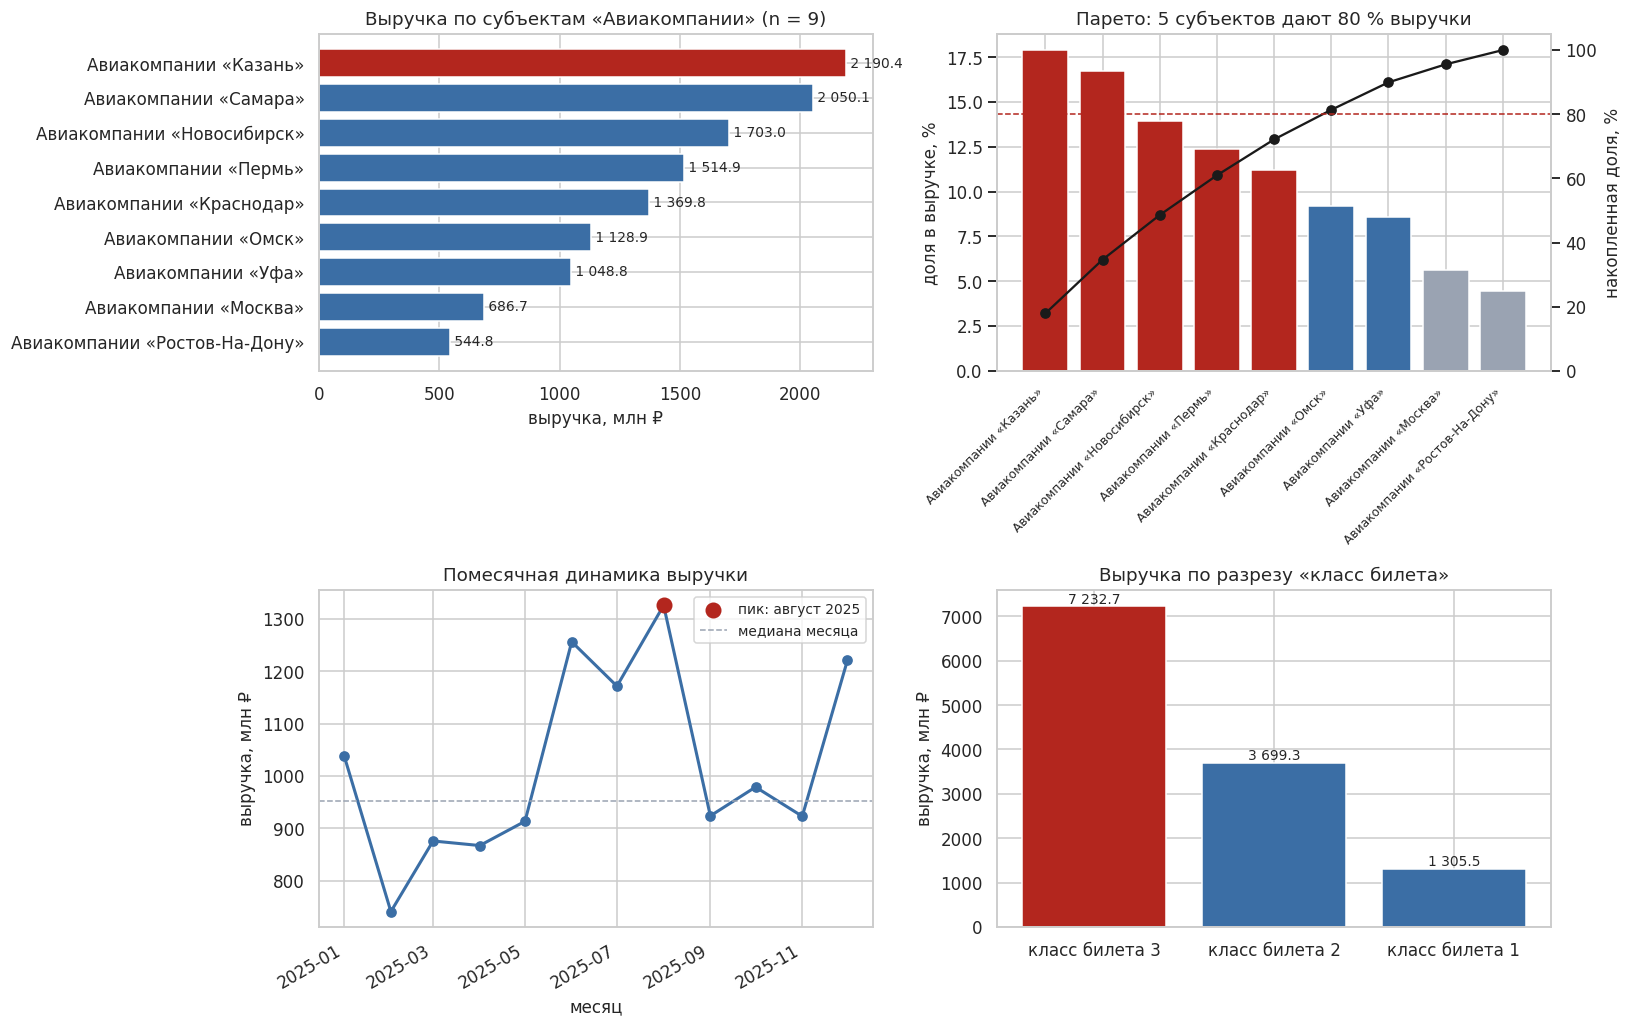

,entity_name,revenue,доля,накопленная доля,группа ABC
0,Авиакомпании «Казань»,"2,190,416,602.38",0.18,0.18,A
1,Авиакомпании «Самара»,"2,050,076,080.63",0.17,0.35,A
2,Авиакомпании «Новосибирск»,"1,703,046,832.21",0.14,0.49,A
3,Авиакомпании «Пермь»,"1,514,902,203.39",0.12,0.61,A
4,Авиакомпании «Краснодар»,"1,369,837,565.32",0.11,0.72,A
5,Авиакомпании «Омск»,"1,128,892,229.01",0.09,0.81,B
6,Авиакомпании «Уфа»,"1,048,769,428.53",0.09,0.90,B
7,Авиакомпании «Москва»,"686,746,954.34",0.06,0.96,C
8,Авиакомпании «Ростов-На-Дону»,"544,755,240.40",0.04,1.00,C



================== ВЫВОДЫ ДЛЯ ЛПР ==================
Предметная область : Авиаперевозки (вариант 1)
Данные             : 3 472 событий, 6 881 строк цен,
                     9 субъектов; в карантине 48 строк (0.5%)
Итоговая выручка   : 12 237 443 136 ₽

1. Концентрация: на три субъекта приходится 49% выручки, лидер — Авиакомпании «Казань»
   (17.9%). Группа A из 5 субъектов формирует 80 % результата — управленческое
   внимание и ресурсы логично распределять в этой пропорции.
2. Сезонность: разрыв между лучшим и худшим месяцем — 1.79 раза, пик приходится
   на август 2025. Планирование мощностей по среднему значению приведёт к дефициту в пик
   и простою в низкий сезон.
3. Качество данных: наивное соединение трёх таблиц завышало выручку в 1.98 раза.
   Отчётность, построенная на таком запросе, дала бы решение по завышенной базе.

Рекомендации:
• Зафиксировать корректную методику расчёта (свёртка цен до уровня события) в регламенте
  отчётности и покрыть её автотестом сверки SQL и pand

In [9]:
#@title Шаг 6. Аналитика и визуализация { display-mode: "form" }
ACCENT, BASE, GREY = "#b3261e", "#3b6ea5", "#9aa3b2"
total_revenue = float(revenue_sql["revenue"].sum())

# ---------------------------------------------------------------- подготовка срезов
top = revenue_sql.sort_values("revenue", ascending=True)
pareto = revenue_sql.sort_values("revenue", ascending=False).copy()
pareto["доля"] = pareto["revenue"] / total_revenue
pareto["накопленная доля"] = pareto["доля"].cumsum()
pareto["группа ABC"] = np.where(pareto["накопленная доля"] <= 0.8, "A",
                        np.where(pareto["накопленная доля"] <= 0.95, "B", "C"))

monthly = (consolidated.assign(month=consolidated["event_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("month", as_index=False)
           .agg(revenue=("event_revenue", "sum"), events=("event_id", "count")))

# Разрез по классам: выручку события делим между его ценовыми строками (иначе fan-out).
by_class = (prices_valid.merge(events_valid[["event_id", "entity_id", "volume_units"]], on="event_id")
            .assign(n_rows=lambda d: d.groupby("event_id")["price_id"].transform("count"))
            .assign(revenue=lambda d: d["volume_units"] * d["unit_price"] / d["n_rows"])
            .groupby("price_class", as_index=False)["revenue"].sum()
            .sort_values("revenue", ascending=False))
class_gap = abs(float(by_class["revenue"].sum()) - total_revenue)
print(f"Контроль сходимости: сумма по разрезу «{CFG['cls']}» отличается от итоговой выручки "
      f"на {class_gap:.2f} ₽ (должно быть 0 с точностью округления)")

# ------------------------------------------------------------------ TODO 6.1
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# 1. Выручка по субъектам, лидер выделен
ax = axes[0, 0]
colors = [ACCENT if i == len(top) - 1 else BASE for i in range(len(top))]
ax.barh(top["entity_name"], top["revenue"] / 1e6, color=colors)
for y, v in enumerate(top["revenue"] / 1e6):
    ax.text(v, y, f" {v:,.1f}".replace(",", " "), va="center", fontsize=9)
ax.set_title(f"Выручка по субъектам «{CFG['parent']}» (n = {len(top)})")
ax.set_xlabel("выручка, млн ₽"); ax.set_ylabel("")

# 2. Парето / ABC
ax = axes[0, 1]
x = np.arange(len(pareto))
ax.bar(x, pareto["доля"] * 100,
       color=[{"A": ACCENT, "B": BASE, "C": GREY}[g] for g in pareto["группа ABC"]])
ax.set_xticks(x, pareto["entity_name"], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("доля в выручке, %")
ax2 = ax.twinx()
ax2.plot(x, pareto["накопленная доля"] * 100, color="#1a1a1a", marker="o", lw=1.5)
ax2.axhline(80, color=ACCENT, ls="--", lw=1)
ax2.set_ylim(0, 105); ax2.set_ylabel("накопленная доля, %"); ax2.grid(False)
n_a = int((pareto["группа ABC"] == "A").sum())
ax.set_title(f"Парето: {n_a} субъектов дают 80 % выручки")

# 3. Сезонность
ax = axes[1, 0]
ax.plot(monthly["month"], monthly["revenue"] / 1e6, marker="o", color=BASE, lw=2)
RU_MONTHS = ["январь", "февраль", "март", "апрель", "май", "июнь",
             "июль", "август", "сентябрь", "октябрь", "ноябрь", "декабрь"]
def ru_month(ts): return f"{RU_MONTHS[ts.month - 1]} {ts.year}"
peak = monthly.loc[monthly["revenue"].idxmax()]
ax.scatter([peak["month"]], [peak["revenue"] / 1e6], color=ACCENT, s=90, zorder=3,
           label=f"пик: {ru_month(peak['month'])}")
ax.axhline(monthly["revenue"].median() / 1e6, color=GREY, ls="--", lw=1, label="медиана месяца")
ax.set_title("Помесячная динамика выручки")
ax.set_xlabel("месяц"); ax.set_ylabel("выручка, млн ₽"); ax.legend(fontsize=9)
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")

# 4. Структура по разрезу
ax = axes[1, 1]
ax.bar(by_class["price_class"], by_class["revenue"] / 1e6,
       color=[ACCENT if i == 0 else BASE for i in range(len(by_class))])
for i, v in enumerate(by_class["revenue"] / 1e6):
    ax.text(i, v, f"{v:,.1f}".replace(",", " "), ha="center", va="bottom", fontsize=9)
ax.set_title(f"Выручка по разрезу «{CFG['cls']}»")
ax.set_xlabel(""); ax.set_ylabel("выручка, млн ₽")
plt.tight_layout(); plt.show()
PLOTS_DONE = True

display(pareto[["entity_name", "revenue", "доля", "накопленная доля", "группа ABC"]].head(10))

# ------------------------------------------------------------------ TODO 6.2
leader = pareto.iloc[0]
share_top3 = float(pareto["доля"].head(3).sum())
season_gap = float(monthly["revenue"].max() / monthly["revenue"].min())
lost_rows = len(quarantine_fk) + len(quarantine_price)
lost_share = lost_rows / max(len(raw_events) + len(raw_prices), 1)

print(f"""
================== ВЫВОДЫ ДЛЯ ЛПР ==================
Предметная область : {CFG['domain']} (вариант {VARIANT})
Данные             : {nf(len(events_valid))} событий, {nf(len(prices_valid))} строк цен,
                     {len(entities)} субъектов; в карантине {lost_rows} строк ({lost_share:.1%})
Итоговая выручка   : {nf(total_revenue)} ₽

1. Концентрация: на три субъекта приходится {share_top3:.0%} выручки, лидер — {leader['entity_name']}
   ({leader['доля']:.1%}). Группа A из {n_a} субъектов формирует 80 % результата — управленческое
   внимание и ресурсы логично распределять в этой пропорции.
2. Сезонность: разрыв между лучшим и худшим месяцем — {season_gap:.2f} раза, пик приходится
   на {ru_month(peak['month'])}. Планирование мощностей по среднему значению приведёт к дефициту в пик
   и простою в низкий сезон.
3. Качество данных: наивное соединение трёх таблиц завышало выручку в {overstate:.2f} раза.
   Отчётность, построенная на таком запросе, дала бы решение по завышенной базе.

Рекомендации:
• Зафиксировать корректную методику расчёта (свёртка цен до уровня события) в регламенте
  отчётности и покрыть её автотестом сверки SQL и pandas.
• Ввести контроль качества на входе: проверка ссылочной целостности и диапазонов значений
  до загрузки в хранилище; карантин разбирать с владельцем источника, а не удалять.
• Планировать ресурсы по помесячному профилю, а не по среднегодовому.
====================================================
""")

**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

In [10]:
revenue_sql.to_csv("/content/pw2/analytical_mart_variant_1.csv", index=False)

## Шаг 7. BigQuery: пошаговое подключение из Colab

Раздел необязателен для зачёта. Он показывает, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [ ]:
#@title Шаг 7 (по желанию). Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "pw2-consolidation"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

Аутентификация в Colab выполнена
Датасет готов: pw2-consolidation.pw2_consolidation (US)
  загружено entities: 8 строк
  загружено events: 2 990 строк
  загружено prices: 5 969 строк

Оценка объёма чтения: 0.17 МБ (бесплатный лимит — 1 ТБ в месяц)


,entity_name,events_cnt,revenue
0,Авиакомпании «Ростов-На-Дону»,593,"2,013,192,875.47"
1,Авиакомпании «Новосибирск»,487,"1,726,767,964.29"
2,Авиакомпании «Тюмень»,467,"1,693,367,469.41"
3,Авиакомпании «Санкт-Петербург»,405,"1,387,468,575.22"
4,Авиакомпании «Омск»,364,"1,318,097,375.78"
5,Авиакомпании «Москва»,265,"925,641,309.98"
6,Авиакомпании «Краснодар»,249,"925,429,872.19"
7,Авиакомпании «Самара»,159,"575,115,970.47"


Максимальное расхождение BigQuery и SQLite: 0.0100


### Шаг 7.1. Графическая сверка расчётов на pandas, SQLite и BigQuery

Ячейка выполняется после шага 7. Если BigQuery не подключён, выводится **фактически доступное** сравнение pandas и SQLite. Она показывает выручку по субъектам и абсолютные расхождения; сходство значений подтверждает корректность SQL-методики, а не одинаковую производительность.


Сверка выручки по субъектам, ₽


,SQLite,pandas,BigQuery
E001 · Ростов-На-Дону,"2,013,192,875.47","2,013,192,875.47","2,013,192,875.47"
E002 · Новосибирск,"1,726,767,964.29","1,726,767,964.29","1,726,767,964.29"
E003 · Тюмень,"1,693,367,469.41","1,693,367,469.41","1,693,367,469.41"
E004 · Санкт-Петербург,"1,387,468,575.22","1,387,468,575.22","1,387,468,575.22"
E005 · Омск,"1,318,097,375.78","1,318,097,375.78","1,318,097,375.78"
E006 · Краснодар,"925,429,872.20","925,429,872.20","925,429,872.19"
E007 · Москва,"925,641,309.98","925,641,309.98","925,641,309.98"
E008 · Самара,"575,115,970.47","575,115,970.46","575,115,970.47"


Максимальная абсолютная разница с SQLite, ₽:


,"расхождение, ₽"
SQLite,0.00
pandas,0.01
BigQuery,0.01


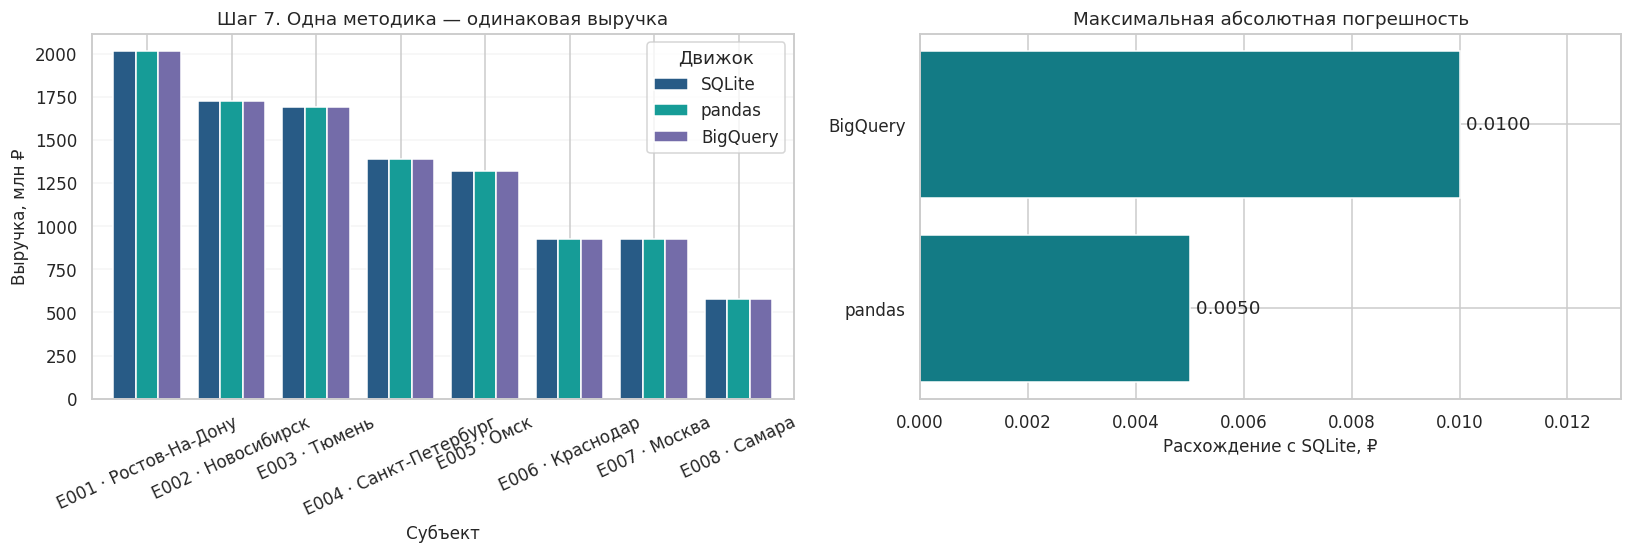

In [ ]:
#@title Шаг 7.1. ГРАФИЧЕСКАЯ СВЕРКА: pandas, SQLite и BigQuery { display-mode: "form" }
# Добавить СРАЗУ после исходной ячейки «Шаг 7 (по желанию). Выгрузка витрины в BigQuery».
from IPython.display import display

engine_series = {
    'SQLite': revenue_sql.set_index('entity_id')['revenue'].astype(float),
    'pandas': revenue_pd.set_index('entity_id')['revenue'].astype(float),
}
if 'revenue_bq' in globals() and isinstance(revenue_bq, pd.DataFrame) and not revenue_bq.empty:
    # В исходном запросе BigQuery нет entity_id, поэтому сопоставляем через имя субъекта.
    mapping = entities.set_index('entity_name')['entity_id']
    bq_plot = revenue_bq.copy()
    bq_plot['entity_id'] = bq_plot['entity_name'].map(mapping)
    assert bq_plot['entity_id'].notna().all(), 'Имена из BigQuery не совпали со справочником'
    engine_series['BigQuery'] = bq_plot.set_index('entity_id')['revenue'].astype(float)
else:
    print('BigQuery не выполнялся: на графике показана подтверждённая сверка SQLite и pandas.')

engine_compare = pd.concat(engine_series, axis=1).sort_index()
assert engine_compare.notna().all().all(), 'Сравниваются разные наборы субъектов'
engine_compare.index = [f"{eid} · {str(entities.set_index('entity_id').loc[eid, 'entity_name']).split('«')[-1].split('»')[0]}" for eid in engine_compare.index]
errors = engine_compare.subtract(engine_compare['SQLite'], axis=0).abs()
print('Сверка выручки по субъектам, ₽')
display(engine_compare.round(2))
print('Максимальная абсолютная разница с SQLite, ₽:')
display(errors.max().round(4).rename('расхождение, ₽').to_frame())
assert errors.max().max() < 1.0, 'Существенное расхождение между движками'

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
engine_compare.div(1e6).plot(kind='bar', ax=axes[0], width=0.8,
                               color=['#285b86', '#169c97', '#746ca9'][:len(engine_series)])
axes[0].set_title('Шаг 7. Одна методика — одинаковая выручка')
axes[0].set_ylabel('Выручка, млн ₽')
axes[0].set_xlabel('Субъект'); axes[0].tick_params(axis='x', labelrotation=25)
axes[0].legend(title='Движок'); axes[0].grid(axis='y', alpha=.2)
errs = errors.drop(columns='SQLite').max().sort_values()
axes[1].barh(errs.index, errs.values, color='#137b85')
axes[1].set_title('Максимальная абсолютная погрешность')
axes[1].set_xlabel('Расхождение с SQLite, ₽')
for i, val in enumerate(errs.values):
    axes[1].text(val, i, f' {val:.4f}', va='center')
axes[1].set_xlim(0, max(float(errs.max()) * 1.30, 0.01))
fig.tight_layout(); plt.show()


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 10 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 20 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 20 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 25 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 15 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 10 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8-9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7-8 | **C** — расчёт верен, но качество данных проработано формально |
| 6-7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [ ]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 балла)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [ ]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.

### Дополнение преподавателя. Решение A–E

Запускайте после основной лабораторной **в таком порядке: C → A → B → D → E**. Пункт C определяет критические автопроверки, поэтому располагается перед инкрементальной загрузкой. Исходные SQLite-таблицы не перезаписываются: для A–D используется отдельная копия базы.

**Особенности:** в исходном JSON нет количества продаж по классам, поэтому пункт D использует воспроизводимый учебный сценарий, а не наблюдаемые продажи. В пункте E график строится только для реально измеренных движков; BigQuery включается вручную и может требовать оплаты ресурсов Google Cloud.


In [ ]:
#@title ★ C. Автотесты качества: остановка конвейера до загрузки { display-mode: "form" }
from IPython.display import display


def validate_clean_batch(entity_df, event_df, price_df):
    """Критичные DQ-правила; AssertionError блокирует загрузку (до SQL-транзакции)."""
    assert not entity_df.empty and not event_df.empty and not price_df.empty, 'Пустой пакет данных'
    # Полнота и уникальность ключей
    for name, frame, key in [('entities', entity_df, 'entity_id'),
                             ('events', event_df, 'event_id'),
                             ('prices', price_df, 'price_id')]:
        assert frame[key].notna().all(), f'{name}: пустые ключи'
        assert frame[key].astype(str).str.strip().ne('').all(), f'{name}: пустые строковые ключи'
        assert frame[key].is_unique, f'{name}: дубликаты первичного ключа'
    assert entity_df['entity_name'].notna().all(), 'Отсутствует название субъекта'
    assert event_df[['entity_id', 'event_date', 'volume_units']].notna().all().all(), 'Пропуски в событиях'
    assert price_df[['event_id', 'unit_price']].notna().all().all(), 'Пропуски в ценах'

    # Согласованность дат и числовых типов
    parsed_date = pd.to_datetime(event_df['event_date'], errors='coerce')
    assert parsed_date.notna().all(), 'Нераспознанная дата события'
    volumes = pd.to_numeric(event_df['volume_units'], errors='coerce').to_numpy(dtype=float)
    unit_prices = pd.to_numeric(price_df['unit_price'], errors='coerce').to_numpy(dtype=float)
    assert np.isfinite(volumes).all() and (volumes > 0).all(), 'Некорректный объём'
    assert np.isfinite(unit_prices).all() and (unit_prices > 0).all(), 'Некорректная цена'

    # Ссылочная целостность: критична до записи в хранилище
    assert event_df['entity_id'].isin(entity_df['entity_id']).all(), 'Событие со ссылкой на неизвестного субъекта'
    assert price_df['event_id'].isin(event_df['event_id']).all(), 'Цена со ссылкой на неизвестное событие'
    # Точность (шаг 3): статистический выброс не доказывает ошибку, поэтому это WARNING.
    q1, q3 = np.quantile(unit_prices, [0.25, 0.75])
    iqr = q3 - q1
    flagged = int(((unit_prices < q1 - 3 * iqr) | (unit_prices > q3 + 3 * iqr)).sum())
    if flagged:
        print(f'⚠️ Некритичная проверка точности: {flagged} экстремальных цен (3×IQR); проверьте источник.')
    return True

# Проверяем очищенные источники, которые уже есть в базовой лабораторной.
assert validate_clean_batch(entities, events_out, prices_valid)
assert not conn.execute('PRAGMA foreign_key_check').fetchall(), 'Нарушены внешние ключи SQLite'
print('✅ DQ-правила (полнота, уникальность, типы, диапазоны, ссылки) пройдены.')

# Демонстрация fail-fast: отрицательная цена останавливает загрузку,
# причём исходные таблицы и база НЕ изменяются.
_bad = prices_valid[['price_id', 'event_id', 'unit_price', 'price_class']].copy()
_bad.loc[_bad.index[0], 'unit_price'] = -1
try:
    validate_clean_batch(entities, events_out, _bad)
    raise RuntimeError('Автотест ошибочно пропустил отрицательную цену')
except AssertionError as exc:
    print('✅ Контрольный негативный тест: конвейер остановлен до INSERT:', exc)
DQ_TESTS_OK = True


✅ DQ-правила (полнота, уникальность, типы, диапазоны, ссылки) пройдены.
✅ Контрольный негативный тест: конвейер остановлен до INSERT: Некорректная цена


Новый день: 2026-01-01; добавлено событий: 12; цен: 24


,этап,событий,цен,"выручка, ₽"
0,до загрузки,2990,5969,"10,565,081,412.81"
1,после 1-го UPSERT,3002,5993,"10,594,861,502.56"
2,после 2-го UPSERT,3002,5993,"10,594,861,502.56"


✅ Повторный UPSERT не создал дубликатов и не изменил выручку.


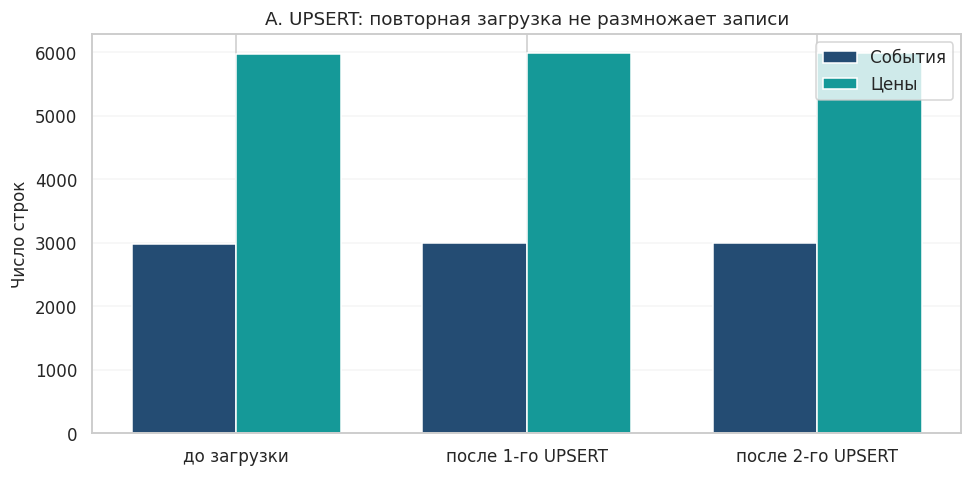

In [ ]:
#@title ★ A. Инкрементальная загрузка и доказательство идемпотентности { display-mode: "form" }
# Базовую БД не меняем: копируем её, чтобы не нарушить шаги 5–7.
STAR_DB = WORK / f'lab2_star_variant_{VARIANT}.sqlite'
if STAR_DB.exists():
    STAR_DB.unlink()
star_conn = sqlite3.connect(STAR_DB)
conn.backup(star_conn)
star_conn.execute('PRAGMA foreign_keys = ON')

rng_a = np.random.default_rng(int(CFG['seed']) + 701)
next_date = (pd.to_datetime(events_out['event_date']).max() + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
n_new = 12
base_event_id = max(int(x[2:]) for x in events_out['event_id'])
base_price_id = max(int(x[2:]) for x in prices_valid['price_id'])
new_eids = [f'EV{base_event_id + i:06d}' for i in range(1, n_new + 1)]
entity_pool = entities['entity_id'].tolist()
inc_events = pd.DataFrame({
    'event_id': new_eids,
    'entity_id': rng_a.choice(entity_pool, size=n_new),
    'event_date': next_date,
    'route': 'Учебное событие: следующий день',
    'volume_units': rng_a.integers(80, 350, n_new).astype(float),
    'asset_type': 'Тип A',
})
price_rows, num = [], base_price_id
available_classes = sorted(prices_valid['price_class'].astype(str).unique())
for eid in new_eids:
    for klass in rng_a.choice(available_classes, size=2, replace=False):
        num += 1
        price_rows.append({'price_id': f'PR{num:07d}', 'event_id': eid,
                           'unit_price': round(float(rng_a.uniform(4000, 12500)), 2),
                           'price_class': klass})
inc_prices = pd.DataFrame(price_rows)

# Автотесты вызываются КАЖДЫЙ раз до начала транзакции.
def upsert_next_day(connection, ev_batch, pr_batch):
    validate_clean_batch(entities, ev_batch, pr_batch)
    with connection:
        connection.executemany("""
            INSERT INTO events(event_id, entity_id, event_date, route, volume_units, asset_type)
            VALUES (:event_id, :entity_id, :event_date, :route, :volume_units, :asset_type)
            ON CONFLICT(event_id) DO UPDATE SET
                entity_id=excluded.entity_id,
                event_date=excluded.event_date,
                route=excluded.route,
                volume_units=excluded.volume_units,
                asset_type=excluded.asset_type""", ev_batch.to_dict('records'))
        connection.executemany("""
            INSERT INTO prices(price_id, event_id, unit_price, price_class)
            VALUES (:price_id, :event_id, :unit_price, :price_class)
            ON CONFLICT(price_id) DO UPDATE SET
                event_id=excluded.event_id,
                unit_price=excluded.unit_price,
                price_class=excluded.price_class""", pr_batch.to_dict('records'))
    assert not connection.execute('PRAGMA foreign_key_check').fetchall(), 'Ошибка FK после UPSERT'


def incremental_state(connection, stage):
    counts = connection.execute('SELECT (SELECT COUNT(*) FROM events), (SELECT COUNT(*) FROM prices)').fetchone()
    sql = """WITH pe AS (SELECT event_id, AVG(unit_price) p FROM prices GROUP BY event_id)
             SELECT COALESCE(ROUND(SUM(ev.volume_units * pe.p), 2), 0)
             FROM events ev JOIN pe ON ev.event_id = pe.event_id"""
    return {'этап': stage, 'событий': counts[0], 'цен': counts[1],
            'выручка, ₽': connection.execute(sql).fetchone()[0]}

incremental_states = [incremental_state(star_conn, 'до загрузки')]
upsert_next_day(star_conn, inc_events, inc_prices)
incremental_states.append(incremental_state(star_conn, 'после 1-го UPSERT'))
upsert_next_day(star_conn, inc_events, inc_prices)
incremental_states.append(incremental_state(star_conn, 'после 2-го UPSERT'))
inc_check = pd.DataFrame(incremental_states)
assert inc_check.loc[1, 'событий'] == inc_check.loc[2, 'событий']
assert inc_check.loc[1, 'цен'] == inc_check.loc[2, 'цен']
assert abs(inc_check.loc[1, 'выручка, ₽'] - inc_check.loc[2, 'выручка, ₽']) < 0.01
assert inc_check.loc[1, 'событий'] - inc_check.loc[0, 'событий'] == n_new
assert inc_check.loc[1, 'цен'] - inc_check.loc[0, 'цен'] == len(inc_prices)
print(f'Новый день: {next_date}; добавлено событий: {n_new}; цен: {len(inc_prices)}')
display(inc_check)
print('✅ Повторный UPSERT не создал дубликатов и не изменил выручку.')

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(inc_check))
ax.bar(x - .18, inc_check['событий'], width=.36, label='События', color='#244c73')
ax.bar(x + .18, inc_check['цен'], width=.36, label='Цены', color='#159998')
ax.set_xticks(x, inc_check['этап']); ax.set_ylabel('Число строк')
ax.set_title('A. UPSERT: повторная загрузка не размножает записи')
ax.legend(); ax.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.show()


Переименование E001 с 2025-07-01: Авиакомпании «Ростов-На-Дону» → Авиакомпании «Ростов-На-Дону» — новое название


,entity_name,valid_from,valid_to,events_cnt,revenue
0,Авиакомпании «Ростов-На-Дону»,1900-01-01,2025-07-01,279,"873,784,690.79"
1,Авиакомпании «Ростов-На-Дону» — новое название,2025-07-01,None,316,"1,145,637,888.36"


✅ Выручка за период до переименования сохранилась: 873,784,690.79 ₽


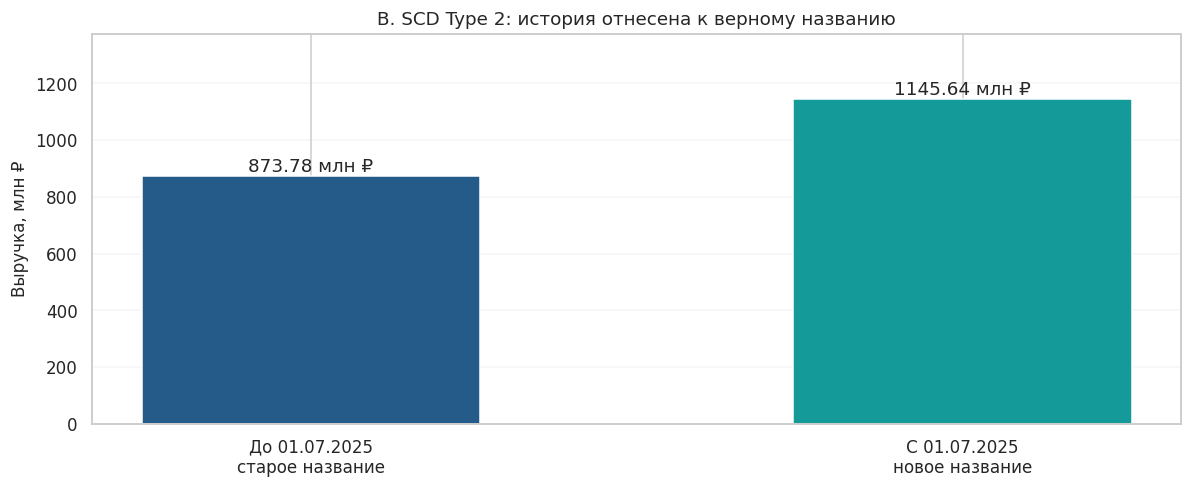

In [ ]:
#@title ★ B. SCD Type 2: история переименования без изменения прошлого { display-mode: "form" }
# SCD-таблица содержит отдельную версию названия на каждый интервал времени.
# Полуоткрытые интервалы [valid_from, valid_to): на границе нет двойного JOIN.
cutoff = '2025-07-01'
entity_stats = pd.read_sql_query("""
    SELECT entity_id,
           SUM(CASE WHEN event_date < ? THEN 1 ELSE 0 END) AS before_cnt,
           SUM(CASE WHEN event_date >= ? THEN 1 ELSE 0 END) AS after_cnt
    FROM events GROUP BY entity_id""", star_conn, params=(cutoff, cutoff))
entity_stats['min_side'] = entity_stats[['before_cnt', 'after_cnt']].min(axis=1)
renamed_id = entity_stats.sort_values('min_side', ascending=False).iloc[0]['entity_id']
old_name = entities.set_index('entity_id').loc[renamed_id, 'entity_name']
new_name = old_name + ' — новое название'

star_conn.executescript("""
CREATE TABLE IF NOT EXISTS entity_history (
  history_id INTEGER PRIMARY KEY AUTOINCREMENT,
  entity_id TEXT NOT NULL REFERENCES entities(entity_id),
  entity_name TEXT NOT NULL,
  valid_from TEXT NOT NULL,
  valid_to TEXT,
  is_current INTEGER NOT NULL CHECK(is_current IN (0,1)),
  CHECK(valid_to IS NULL OR valid_to > valid_from),
  UNIQUE(entity_id, valid_from)
);
CREATE UNIQUE INDEX IF NOT EXISTS uq_entity_current
ON entity_history(entity_id) WHERE is_current = 1;
""")
star_conn.execute('DELETE FROM entity_history')
with star_conn:
    star_conn.executemany("""
        INSERT INTO entity_history(entity_id, entity_name, valid_from, valid_to, is_current)
        VALUES (?, ?, '1900-01-01', NULL, 1)""",
        list(entities[['entity_id', 'entity_name']].itertuples(index=False, name=None)))

# До изменения: фиксируем историческую выручку выбранного субъекта.
period_sql = """WITH pe AS (SELECT event_id, AVG(unit_price) avg_price FROM prices GROUP BY event_id)
 SELECT ROUND(SUM(ev.volume_units * pe.avg_price), 2)
 FROM events ev JOIN pe ON pe.event_id=ev.event_id
 WHERE ev.entity_id=? AND ev.event_date < ?"""
history_before = float(star_conn.execute(period_sql, (renamed_id, cutoff)).fetchone()[0] or 0)

with star_conn:
    star_conn.execute("""UPDATE entity_history
                         SET valid_to=?, is_current=0
                         WHERE entity_id=? AND is_current=1""", (cutoff, renamed_id))
    star_conn.execute("""INSERT INTO entity_history
                         (entity_id, entity_name, valid_from, valid_to, is_current)
                         VALUES (?, ?, ?, NULL, 1)""", (renamed_id, new_name, cutoff))

# Связываем СОБЫТИЕ с названием, действовавшим в его дату, а не с текущим именем.
scd_sql = """WITH pe AS (SELECT event_id, AVG(unit_price) avg_price FROM prices GROUP BY event_id)
SELECT h.entity_name, h.valid_from, h.valid_to,
       COUNT(*) AS events_cnt, ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
FROM events ev JOIN pe ON pe.event_id=ev.event_id
JOIN entity_history h ON h.entity_id=ev.entity_id
 AND ev.event_date >= h.valid_from
 AND (h.valid_to IS NULL OR ev.event_date < h.valid_to)
WHERE ev.entity_id=?
GROUP BY h.history_id, h.entity_name, h.valid_from, h.valid_to
ORDER BY h.valid_from"""
scd_result = pd.read_sql_query(scd_sql, star_conn, params=(renamed_id,))
assert len(scd_result) == 2, 'Не обнаружены обе исторические версии названия'
assert abs(scd_result.loc[0, 'revenue'] - history_before) < 0.01, 'Историческая выручка изменилась!'
assert scd_result.loc[0, 'entity_name'] == old_name
assert scd_result.loc[1, 'entity_name'] == new_name
print(f'Переименование {renamed_id} с {cutoff}: {old_name} → {new_name}')
display(scd_result)
print(f'✅ Выручка за период до переименования сохранилась: {history_before:,.2f} ₽')

fig, ax = plt.subplots(figsize=(11, 4.6))
labels = ['До 01.07.2025\nстарое название', 'С 01.07.2025\nновое название']
bars = ax.bar(labels, scd_result['revenue'] / 1e6, color=['#245b88','#149a99'], width=.52)
for bar, val in zip(bars, scd_result['revenue'] / 1e6):
    ax.text(bar.get_x()+bar.get_width()/2, val, f'{val:.2f} млн ₽', ha='center', va='bottom')
ax.set_title('B. SCD Type 2: история отнесена к верному названию')
ax.set_ylabel('Выручка, млн ₽'); ax.grid(axis='y', alpha=.2)
ax.set_ylim(0, max(scd_result['revenue'])/1e6 * 1.2)
plt.tight_layout(); plt.show()


Взвешенное среднее основано на СМОДЕЛИРОВАННОМ распределении проданных единиц.


,entity_id,entity_name,revenue,revenue_weighted,units_sold,"разница, ₽","изменение, %"
0,E001,Авиакомпании «Ростов-На-Дону»,"2,013,192,875.47","1,616,852,469.31",124876,"-396,340,406.16",-19.69
1,E002,Авиакомпании «Новосибирск»,"1,726,767,964.29","1,372,862,078.91",102080,"-353,905,885.38",-20.50
2,E003,Авиакомпании «Тюмень»,"1,693,367,469.41","1,406,885,545.18",99052,"-286,481,924.23",-16.92
3,E004,Авиакомпании «Санкт-Петербург»,"1,387,468,575.22","1,152,330,668.18",85406,"-235,137,907.04",-16.95
4,E005,Авиакомпании «Омск»,"1,318,097,375.78","1,082,418,781.69",75617,"-235,678,594.09",-17.88
5,E007,Авиакомпании «Москва»,"925,641,309.98","759,920,052.77",54758,"-165,721,257.21",-17.90
6,E006,Авиакомпании «Краснодар»,"925,429,872.20","746,411,535.71",53338,"-179,018,336.49",-19.34
7,E008,Авиакомпании «Самара»,"575,115,970.47","481,469,767.12",32627,"-93,646,203.35",-16.28


Простое среднее: 10,565,081,412.82 ₽ | Взвешенное: 8,619,150,898.87 ₽ | Изменение: -18.42%


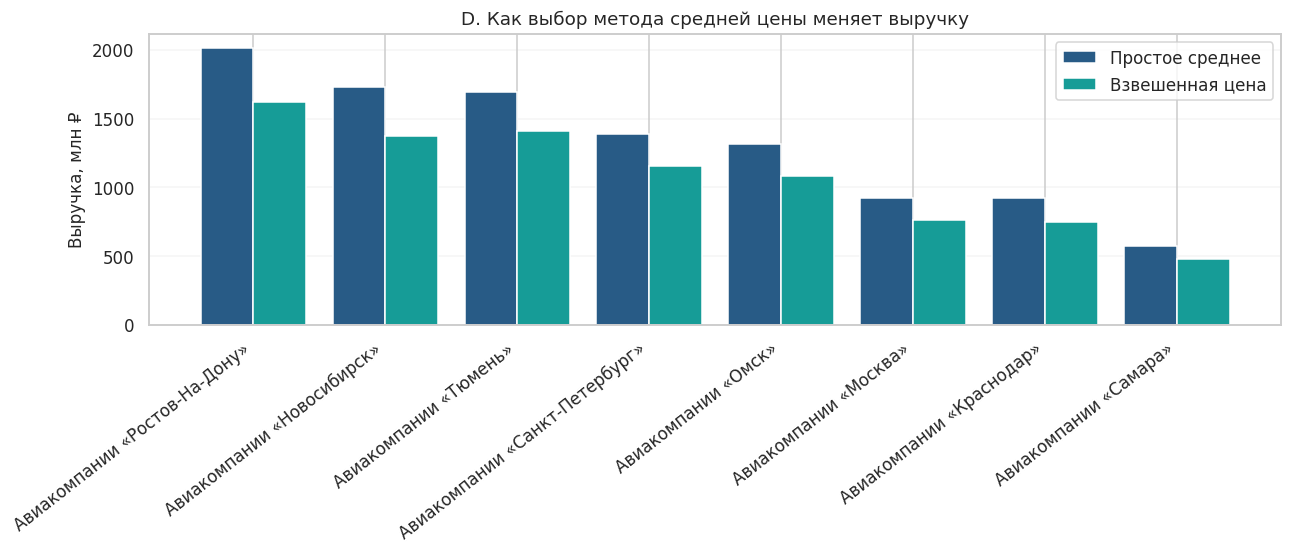

In [ ]:
#@title ★ D. Цена по количеству проданных единиц: средняя против взвешенной { display-mode: "form" }
# В исходном JSON НЕТ количества по классам. Ниже генерируем учебный сценарий:
# дешёвые тарифы/классы получают больше единиц продаж. Это гипотеза, НЕ факт из источника!
rng_d = np.random.default_rng(int(CFG['seed']) + 703)
vol_by_event = events_valid.set_index('event_id')['volume_units'].astype(int)
alloc_rows = []
for event_id, group in prices_valid.groupby('event_id', sort=False):
    volumes = int(vol_by_event.loc[event_id])
    assert volumes >= len(group), 'Объём меньше числа ценовых строк'
    price_values = group['unit_price'].to_numpy(dtype=float)
    preference = 1 / np.power(price_values, 1.2)
    preference = preference / preference.sum()
    # Минимум 1 единица на каждую ценовую строку; все остальные — multinomial.
    sold = 1 + rng_d.multinomial(volumes - len(group), preference)
    for price_id, units in zip(group['price_id'], sold):
        alloc_rows.append((str(price_id), str(event_id), int(units)))
alloc_df = pd.DataFrame(alloc_rows, columns=['price_id', 'event_id', 'sold_units'])

with star_conn:
    star_conn.execute("""CREATE TABLE IF NOT EXISTS sold_allocations (
        price_id TEXT PRIMARY KEY REFERENCES prices(price_id),
        event_id TEXT NOT NULL REFERENCES events(event_id),
        sold_units INTEGER NOT NULL CHECK(sold_units > 0))""")
    star_conn.execute('DELETE FROM sold_allocations')
    star_conn.executemany('INSERT INTO sold_allocations(price_id, event_id, sold_units) VALUES (?,?,?)', alloc_rows)
assert (alloc_df.groupby('event_id')['sold_units'].sum().sort_index().values ==
        vol_by_event.loc[alloc_df['event_id'].unique()].sort_index().values).all(), 'Проданный объём не сошёлся'

# Взвешенная цена события: SUM(цена_класса × продано_класса) / SUM(продано_класса).
weighted_sql = """
WITH priced_event AS (
  SELECT a.event_id,
         SUM(p.unit_price * a.sold_units) AS event_revenue,
         SUM(a.sold_units) AS units_sold
  FROM sold_allocations a JOIN prices p ON p.price_id = a.price_id
  GROUP BY a.event_id
)
SELECT ev.entity_id, ROUND(SUM(pe.event_revenue), 2) AS revenue_weighted,
       SUM(pe.units_sold) AS units_sold
FROM events ev JOIN priced_event pe ON pe.event_id=ev.event_id
GROUP BY ev.entity_id ORDER BY ev.entity_id"""
rev_weighted = pd.read_sql_query(weighted_sql, star_conn)
weighted_comparison = revenue_sql[['entity_id', 'entity_name', 'revenue']].merge(rev_weighted, on='entity_id')
weighted_comparison['разница, ₽'] = weighted_comparison['revenue_weighted'] - weighted_comparison['revenue']
weighted_comparison['изменение, %'] = (100 * weighted_comparison['разница, ₽'] /
                                       weighted_comparison['revenue'])
print('Взвешенное среднее основано на СМОДЕЛИРОВАННОМ распределении проданных единиц.')
display(weighted_comparison.round(2))
plain_total = float(weighted_comparison['revenue'].sum())
weighted_total = float(weighted_comparison['revenue_weighted'].sum())
assert abs(plain_total - float(revenue_sql['revenue'].sum())) < 0.01
print(f'Простое среднее: {plain_total:,.2f} ₽ | Взвешенное: {weighted_total:,.2f} ₽ | '
      f'Изменение: {100*(weighted_total/plain_total-1):+.2f}%')

wc = weighted_comparison.sort_values('revenue', ascending=False)
x = np.arange(len(wc)); width = .40
fig, ax = plt.subplots(figsize=(12, 5.2))
ax.bar(x-width/2, wc['revenue']/1e6, width, label='Простое среднее', color='#285b86')
ax.bar(x+width/2, wc['revenue_weighted']/1e6, width, label='Взвешенная цена', color='#169c97')
ax.set_xticks(x, wc['entity_name'], rotation=38, ha='right')
ax.set_ylabel('Выручка, млн ₽'); ax.set_title('D. Как выбор метода средней цены меняет выручку')
ax.legend(); ax.grid(axis='y', alpha=.2)
plt.tight_layout(); plt.show()


1×: 2,990 событий, 5,969 цен | pandas=3.9 мс, SQLite=5.3 мс | сверка=0.0050 ₽
10×: 29,900 событий, 59,690 цен | pandas=19.2 мс, SQLite=65.7 мс | сверка=0.0033 ₽
BigQuery dry_run: 2.05 МБ чтения


,масштаб,движок,"время, мс"
4,10×,BigQuery,"1,621.42"
3,10×,SQLite,65.72
2,10×,pandas,19.24
1,1×,SQLite,5.32
0,1×,pandas,3.90


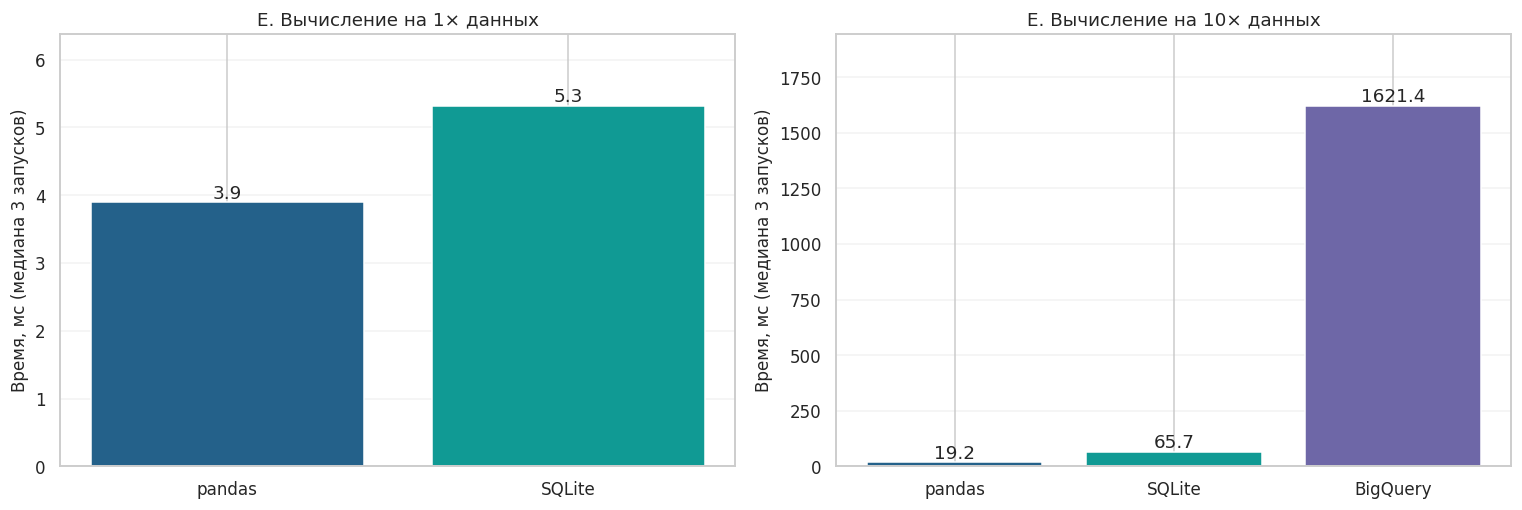

Вывод: это локальный бенчмарк вычислений, а не универсальный рейтинг. Для малых данных существенны накладные расходы BigQuery; на больших данных граница зависит от RAM, индексов, сети, параллелизма и сложности запроса.


In [ ]:
#@title ★ E. Сравнение pandas / SQLite / BigQuery: 1× и 10×, с графиком { display-mode: "form" }
#@markdown BigQuery не запускается автоматически: удалённое исполнение может быть платным.
RUN_BIGQUERY_BENCHMARK = True  #@param {type:"boolean"}
from time import perf_counter

# 10 независимых копий исходных ОЧИЩЕННЫХ данных: состав, арифметика и FK сохраняются.
bench_events_1x = events_out[['event_id', 'entity_id', 'volume_units']].copy()
bench_prices_1x = prices_valid[['price_id', 'event_id', 'unit_price']].copy()

def enlarge(times):
    event_parts, price_parts = [], []
    for rep in range(times):
        suffix = f'_R{rep:02d}'
        ev = bench_events_1x.copy()
        pr = bench_prices_1x.copy()
        ev['event_id'] += suffix
        pr['event_id'] += suffix
        pr['price_id'] += suffix
        event_parts.append(ev); price_parts.append(pr)
    return pd.concat(event_parts, ignore_index=True), pd.concat(price_parts, ignore_index=True)

bench_events_10x, bench_prices_10x = enlarge(10)
assert len(bench_events_10x) == 10 * len(bench_events_1x)
assert len(bench_prices_10x) == 10 * len(bench_prices_1x)
assert bench_events_10x['event_id'].is_unique and bench_prices_10x['price_id'].is_unique


def pandas_revenue(ee, pp):
    mean_prices = pp.groupby('event_id', sort=False)['unit_price'].mean()
    frame = ee.merge(mean_prices.rename('mean_price'), left_on='event_id', right_index=True, how='inner')
    frame['product'] = frame['volume_units'] * frame['mean_price']
    return frame.groupby('entity_id')['product'].sum().sort_index()

sql_bench = """WITH pe AS (SELECT event_id, AVG(unit_price) mean_price
                         FROM bench_prices GROUP BY event_id)
    SELECT ev.entity_id, ROUND(SUM(ev.volume_units * pe.mean_price), 2) AS revenue
    FROM bench_events ev JOIN pe ON pe.event_id=ev.event_id
    GROUP BY ev.entity_id ORDER BY ev.entity_id"""


def create_bench_db(ee, pp):
    con = sqlite3.connect(':memory:')
    ee.to_sql('bench_events', con, index=False)
    pp.to_sql('bench_prices', con, index=False)
    con.execute('CREATE INDEX ix_bench_price_event ON bench_prices(event_id)')
    con.execute('CREATE INDEX ix_bench_event_entity ON bench_events(entity_id)')
    return con

bench_conn_1x = create_bench_db(bench_events_1x, bench_prices_1x)
bench_conn_10x = create_bench_db(bench_events_10x, bench_prices_10x)


def timed(fn, repeats=3):
    measurements = []
    result = None
    for _ in range(repeats):
        started = perf_counter()
        result = fn()
        measurements.append((perf_counter() - started) * 1000)
    return float(np.median(measurements)), result

bench_data = []
for scale, ee, pp, con in [
    ('1×', bench_events_1x, bench_prices_1x, bench_conn_1x),
    ('10×', bench_events_10x, bench_prices_10x, bench_conn_10x)]:
    pd_ms, pd_result = timed(lambda: pandas_revenue(ee, pp))
    sql_ms, sql_result = timed(lambda: pd.read_sql_query(sql_bench, con))
    sql_result = sql_result.set_index('entity_id')['revenue'].sort_index()
    max_gap = float((pd_result - sql_result).abs().max())
    assert max_gap < 1.0, f'{scale}: разошлись pandas и SQLite: {max_gap:.3f} ₽'
    bench_data.extend([{'масштаб': scale, 'движок': 'pandas', 'время, мс': pd_ms},
                       {'масштаб': scale, 'движок': 'SQLite', 'время, мс': sql_ms}])
    print(f'{scale}: {len(ee):,} событий, {len(pp):,} цен | '
          f'pandas={pd_ms:.1f} мс, SQLite={sql_ms:.1f} мс | сверка={max_gap:.4f} ₽')

# Не включаем загрузку из Colab в SQL-расчёт: сравниваем ТОЛЬКО выполнение аналитики.
# Для BigQuery отдельно загружаем 10× таблицы (этап ETL), затем замеряем SQL+получение результата.
if RUN_BIGQUERY_BENCHMARK:
    if 'client' not in globals() or 'bigquery' not in globals():
        raise RuntimeError('Сначала выполните шаг 7: авторизация BigQuery и создание client.')
    table_events = f'{BQ_PROJECT_ID}.{BQ_DATASET}.bench_events_10x'
    table_prices = f'{BQ_PROJECT_ID}.{BQ_DATASET}.bench_prices_10x'
    for target, frame in [(table_events, bench_events_10x), (table_prices, bench_prices_10x)]:
        job = client.load_table_from_dataframe(
            frame, target,
            job_config=bigquery.LoadJobConfig(write_disposition='WRITE_TRUNCATE'))
        job.result()
    bq_bench_sql = f"""WITH pe AS (SELECT event_id, AVG(unit_price) AS mean_price
                          FROM `{table_prices}` GROUP BY event_id)
        SELECT ev.entity_id, ROUND(SUM(ev.volume_units * pe.mean_price), 2) revenue
        FROM `{table_events}` ev JOIN pe ON ev.event_id=pe.event_id
        GROUP BY ev.entity_id ORDER BY ev.entity_id"""
    dry = client.query(bq_bench_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f'BigQuery dry_run: {dry.total_bytes_processed / 1024**2:.2f} МБ чтения')
    def bq_execute():
        job = client.query(bq_bench_sql, job_config=bigquery.QueryJobConfig(use_query_cache=False))
        return job.to_dataframe()
    bq_ms, bq_result = timed(bq_execute, repeats=3)
    bq_series = bq_result.set_index('entity_id')['revenue'].astype(float).sort_index()
    sqlite_series = pd.read_sql_query(sql_bench, bench_conn_10x).set_index('entity_id')['revenue'].sort_index()
    assert (bq_series - sqlite_series).abs().max() < 1.0, 'BigQuery и SQLite расходятся'
    bench_data.append({'масштаб': '10×', 'движок': 'BigQuery', 'время, мс': bq_ms})
else:
    print('BigQuery пропущен: для его измерения включите RUN_BIGQUERY_BENCHMARK.')

bench_result = pd.DataFrame(bench_data)
display(bench_result.sort_values(['масштаб', 'движок']))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
# График 1: только реально измеренные времена, без имитации BigQuery.
for i, scale in enumerate(['1×', '10×']):
    dfscale = bench_result[bench_result['масштаб'] == scale]
    axes[i].bar(dfscale['движок'], dfscale['время, мс'], color=[
        {'pandas':'#24618a', 'SQLite':'#109a94','BigQuery':'#6e67a7'}[v]
        for v in dfscale['движок']])
    axes[i].set_title(f'E. Вычисление на {scale} данных')
    axes[i].set_ylabel('Время, мс (медиана 3 запусков)')
    axes[i].grid(axis='y', alpha=.25)
    for j, value in enumerate(dfscale['время, мс']):
        axes[i].text(j, value, f'{value:.1f}', ha='center', va='bottom')
    axes[i].set_ylim(0, max(dfscale['время, мс']) * 1.20)
plt.tight_layout(); plt.show()
print('Вывод: это локальный бенчмарк вычислений, а не универсальный рейтинг. '
      'Для малых данных существенны накладные расходы BigQuery; на больших данных '
      'граница зависит от RAM, индексов, сети, параллелизма и сложности запроса.')


### Краткие педагогические выводы

- **A:** два запуска одного UPSERT создают ровно один набор новых ключей; число строк и выручка на втором запуске не меняются.
- **B:** интервал `valid_from ≤ event_date < valid_to` связывает исторические события с тем названием, которое действовало в соответствующую дату.
- **C:** `assert` останавливает запись критически некорректного пакета *до* транзакции; некритичные отклонения должны фиксироваться отдельно в журнале.
- **D:** `Σ(price × units) / Σ(units)` учитывает структуру продаж, в отличие от простого `AVG(price)`; в работе объёмы по классам моделируются.
- **E:** медиана повторных замеров иллюстрирует производительность на конкретной машине; для BigQuery важны время сети, удалённый запуск, стоимость и тип рабочего запроса.
